In [9]:
DATA_MODE = "multi30k"
RUN_FULL_TRAINING = True

Lab — Concatenate Attention for German-to-English Translation
Name: Anant Arya
Roll number: A24ARIU0014

Completed implementations of masked concatenate attention, greedy decoding, and beam search. Run all cells in order. The default smoke mode uses tiny built-in examples without downloading data; it checks execution, not translation quality. For the assessed comparison, change DATA_MODE to "multi30k" and RUN_FULL_TRAINING to True, then restart and run all cells. Real metrics and visual observations are produced by that run; none are invented here.

In [10]:
import random, re, math, json, importlib.util, subprocess, sys
from collections import Counter
from pathlib import Path
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

SEED = 17
DATA_MODE = "smoke"           # "smoke" or "multi30k"
RUN_FULL_TRAINING = False      # True for Multi30k comparison
MAX_TRAIN_PAIRS = 12000        # None uses the full training split
EPOCHS = 8
TEST_EVAL_LIMIT = 200
OUTPUT_DIR = Path("seq2seq_attention_outputs")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_all():
    random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
assert not RUN_FULL_TRAINING or DATA_MODE == "multi30k"
print("Device:", device, "| mode:", DATA_MODE, "| full training:", RUN_FULL_TRAINING)

SMOKE_TRAIN = [
    ("das buch ist rot", "the book is red"),
    ("das auto ist blau", "the car is blue"),
    ("das haus ist grün", "the house is green"),
    ("das boot ist gelb", "the boat is yellow"),
    ("ein mann geht", "a man walks"),
    ("eine frau geht", "a woman walks"),
    ("ein mann läuft", "a man runs"),
    ("eine frau läuft", "a woman runs"),
]

def normalized(text): return " ".join(text.lower().split())
def remove_seen_sources(pairs, seen):
    kept = []
    for source, target in pairs:
        key = normalized(source)
        if key not in seen:
            kept.append((source, target)); seen.add(key)
    return kept

if DATA_MODE == "smoke":
    train_pairs = SMOKE_TRAIN
    valid_pairs = [("das auto ist rot", "the car is red")]
    test_pairs = [("das buch ist blau", "the book is blue")]
elif DATA_MODE == "multi30k":
    # Install only the packages needed for full-data training/evaluation.
    for package in ("datasets", "sacrebleu", "matplotlib"):
        if importlib.util.find_spec(package) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
    from datasets import load_dataset
    raw = load_dataset("bentrevett/multi30k")
    train_pairs = [(r["de"], r["en"]) for r in raw["train"]]
    random.Random(SEED).shuffle(train_pairs)
    if MAX_TRAIN_PAIRS is not None: train_pairs = train_pairs[:MAX_TRAIN_PAIRS]
    seen = {normalized(s) for s, _ in train_pairs}
    valid_pairs = remove_seen_sources([(r["de"], r["en"]) for r in raw["validation"]], seen)
    test_pairs = remove_seen_sources([(r["de"], r["en"]) for r in raw["test"]], seen)
else:
    raise ValueError("DATA_MODE must be smoke or multi30k")
print("Train / validation / test:", len(train_pairs), len(valid_pairs), len(test_pairs))

Device: cpu | mode: smoke | full training: False
Train / validation / test: 8 1 1


In [11]:
SPECIALS = ["<pad>", "<unk>", "<sos>", "<eos>"]
PAD, UNK, SOS, EOS = range(4)

def tokenize(text):
    return re.findall(r"[^\W_]+|[^\w\s]", text.lower(), flags=re.UNICODE)

def build_vocab(texts):
    counts = Counter(t for text in texts for t in tokenize(text))
    vocab = {token: i for i, token in enumerate(SPECIALS)}
    for token, count in counts.most_common():
        if count >= (1 if DATA_MODE == "smoke" else 2) and len(vocab) < 6000:
            if token not in vocab: vocab[token] = len(vocab)
    return vocab

src_vocab = build_vocab(s for s, _ in train_pairs)
tgt_vocab = build_vocab(t for _, t in train_pairs)
tgt_itos = {i: t for t, i in tgt_vocab.items()}

def encode_text(text, vocab):
    return [SOS] + [vocab.get(t, UNK) for t in tokenize(text)] + [EOS]

class PairDataset(Dataset):
    def __init__(self, pairs): self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, index):
        source, target = self.pairs[index]
        return torch.tensor(encode_text(source, src_vocab)), torch.tensor(encode_text(target, tgt_vocab))

def collate(batch):
    sources, targets = zip(*batch)
    lengths = torch.tensor([len(s) for s in sources])
    return (nn.utils.rnn.pad_sequence(sources, batch_first=True, padding_value=PAD),
            lengths,
            nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=PAD))

BATCH_SIZE = 2 if DATA_MODE == "smoke" else 64
def make_train_loader():
    # A fresh seeded generator gives both models the same batch order.
    return DataLoader(PairDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True,
                      collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
train_loader = make_train_loader()
valid_loader = DataLoader(PairDataset(valid_pairs), batch_size=BATCH_SIZE, collate_fn=collate)
print("German / English vocabulary:", len(src_vocab), len(tgt_vocab))

German / English vocabulary: 20 19


2. Exercise 1 — shapes and decoder inputs
Quantity	Shape
Source token IDs	[B, Tx]
Encoder outputs	[B, Tx, H]
Final encoder hidden/cell state	[1, B, H]
Top decoder hidden state (query)	[B, H]
Concatenated query and encoder outputs	[B, Tx, 2H]
Scores / attention weights	[B, Tx]
Context	[B, H]
Training logits	[B, Ty−1, Vy]


At target step t, the input is the previous token (t−1), starting with <sos>. Supplying the current target would leak the answer and would not match autoregressive generation.

In [12]:
EMB_DIM = 64 if DATA_MODE == "smoke" else 128
HIDDEN_DIM = 64 if DATA_MODE == "smoke" else 256

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(src_vocab), EMB_DIM, padding_idx=PAD)
        self.lstm = nn.LSTM(EMB_DIM, HIDDEN_DIM, batch_first=True)
    def forward(self, source, lengths):
        embedded = self.embedding(source)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_outputs, states = self.lstm(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True, total_length=source.size(1))
        return outputs, states

class ConcatAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.alignment = nn.Linear(2 * hidden_dim, hidden_dim)
        self.score = nn.Linear(hidden_dim, 1, bias=False)
    def forward(self, query, encoder_outputs, src_mask):
        query = query.unsqueeze(1).expand(-1, encoder_outputs.size(1), -1)
        combined = torch.cat([query, encoder_outputs], dim=-1)
        scores = self.score(torch.tanh(self.alignment(combined))).squeeze(-1)
        scores = scores.masked_fill(~src_mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)
        return context, weights

class Decoder(nn.Module):
    def __init__(self, with_attention):
        super().__init__()
        self.embedding = nn.Embedding(len(tgt_vocab), EMB_DIM, padding_idx=PAD)
        self.attention = ConcatAttention(HIDDEN_DIM) if with_attention else None
        context_dim = HIDDEN_DIM if with_attention else 0
        self.lstm = nn.LSTM(EMB_DIM + context_dim, HIDDEN_DIM, batch_first=True)
        self.fc_out = nn.Linear(HIDDEN_DIM + context_dim, len(tgt_vocab))
    def forward(self, previous, hidden, cell, encoder_outputs, mask):
        embedded = self.embedding(previous).unsqueeze(1)
        context = weights = None
        if self.attention is not None:
            context, weights = self.attention(hidden[-1], encoder_outputs, mask)
            embedded = torch.cat([embedded, context.unsqueeze(1)], dim=-1)
        output, (hidden, cell) = self.lstm(embedded, (hidden, cell))
        output = output.squeeze(1)
        if context is not None: output = torch.cat([output, context], dim=-1)
        return self.fc_out(output), hidden, cell, weights

class Seq2Seq(nn.Module):
    def __init__(self, with_attention=False):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder(with_attention)
    def forward(self, source, lengths, target, teacher_forcing_ratio=0.5):
        encoder_outputs, (hidden, cell) = self.encoder(source, lengths)
        previous = target[:, 0]
        logits_list = []
        for t in range(1, target.size(1)):
            logits, hidden, cell, _ = self.decoder(previous, hidden, cell, encoder_outputs, source.ne(PAD))
            logits_list.append(logits)
            previous = target[:, t] if random.random() < teacher_forcing_ratio else logits.argmax(-1)
        return torch.stack(logits_list, dim=1)

ATTENTION_READY = True
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

# Check real padding explicitly, including normalization and zero padding weights.
check_attention = ConcatAttention(HIDDEN_DIM).to(device)
check_outputs = torch.randn(2, 5, HIDDEN_DIM, device=device, requires_grad=True)
mask = torch.tensor([[True, True, True, False, False], [True]*5], device=device)
context, weights = check_attention(torch.randn(2, HIDDEN_DIM, device=device), check_outputs, mask)
assert context.shape == (2, HIDDEN_DIM) and weights.shape == (2, 5)
assert torch.allclose(weights.sum(1), torch.ones(2, device=device), atol=1e-5)
assert torch.all(weights[~mask] == 0)
context.square().mean().backward()
assert check_attention.alignment.weight.grad is not None
assert check_attention.score.weight.grad is not None
assert check_outputs.grad is not None

check_model = Seq2Seq(True).to(device)
s, n, t = [x.to(device) for x in next(iter(make_train_loader()))]
logits = check_model(s, n, t, 1.0)
assert logits.shape == (s.size(0), t.size(1)-1, len(tgt_vocab))
criterion(logits.reshape(-1, len(tgt_vocab)), t[:, 1:].reshape(-1)).backward()
assert check_model.encoder.lstm.weight_ih_l0.grad is not None
print("Attention shapes, padding mask, and gradient checks passed")
del check_model, check_attention

Attention shapes, padding mask, and gradient checks passed


4. Training and greedy decoding

In [13]:
def run_epoch(model, loader, optimizer=None, max_batches=None):
    model.train(optimizer is not None)
    total_loss = total_tokens = 0
    for index, (source, lengths, target) in enumerate(loader):
        if max_batches is not None and index >= max_batches: break
        source, lengths, target = source.to(device), lengths.to(device), target.to(device)
        if optimizer is not None: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(optimizer is not None):
            logits = model(source, lengths, target, 0.5 if optimizer is not None else 1.0)
            gold = target[:, 1:]
            loss = criterion(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
            if optimizer is not None:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        tokens = gold.ne(PAD).sum().item()
        total_loss += loss.item() * tokens
        total_tokens += tokens
    return total_loss / total_tokens

def source_tensor(text):
    ids = encode_text(text, src_vocab)
    return torch.tensor([ids], device=device), torch.tensor([len(ids)])

@torch.no_grad()
def greedy_translate(model, source_text, max_steps=40):
    model.eval()
    source, lengths = source_tensor(source_text)
    outputs, (hidden, cell) = model.encoder(source, lengths)
    previous = torch.tensor([SOS], device=device)
    tokens, rows = [], []
    for _ in range(max_steps):
        logits, hidden, cell, weights = model.decoder(previous, hidden, cell, outputs, source.ne(PAD))
        previous = logits.argmax(-1)
        if previous.item() == EOS: break
        tokens.append(tgt_itos[previous.item()])
        if weights is not None: rows.append(weights[0].cpu())
    return tokens, torch.stack(rows) if rows else None

def train_model(with_attention):
    seed_all()
    model = Seq2Seq(with_attention).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_train_loader()
    history, best_state, best_loss, stale = [], None, float("inf"), 0
    for epoch in range(EPOCHS if RUN_FULL_TRAINING else 1):
        train_loss = run_epoch(model, loader, optimizer, None if RUN_FULL_TRAINING else 2)
        valid_loss = run_epoch(model, valid_loader)
        history.append((train_loss, valid_loss))
        print(f"{'attention' if with_attention else 'baseline'} {epoch+1}: train={train_loss:.3f}, valid={valid_loss:.3f}")
        if valid_loss < best_loss:
            best_loss, stale = valid_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= 3: break
    model.load_state_dict(best_state)
    return model, history

baseline, baseline_history = train_model(False)
attention_model, attention_history = train_model(True)
print("Parameters — baseline:", sum(p.numel() for p in baseline.parameters()),
      "attention:", sum(p.numel() for p in attention_model.parameters()))
if not RUN_FULL_TRAINING: print("SMOKE ONLY: two training batches per model; quality is not evaluated.")
if RUN_FULL_TRAINING:
    import matplotlib.pyplot as plt
    OUTPUT_DIR.mkdir(exist_ok=True)
    configuration = dict(seed=SEED, data_mode=DATA_MODE, max_train_pairs=MAX_TRAIN_PAIRS,
        epochs=EPOCHS, batch_size=BATCH_SIZE, embedding=EMB_DIM, hidden=HIDDEN_DIM,
        teacher_forcing=0.5, learning_rate=1e-3, test_limit=TEST_EVAL_LIMIT,
        train_size=len(train_pairs), valid_size=len(valid_pairs), test_size=len(test_pairs))
    (OUTPUT_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2))
    for name, history in [("baseline", baseline_history), ("attention", attention_history)]:
        plt.plot(range(1,len(history)+1), [v for _,v in history], marker="o", label=name)
    plt.xlabel("Epoch"); plt.ylabel("Teacher-forced validation cross-entropy"); plt.legend()
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "validation_losses.png"); plt.show()

baseline 1: train=2.968, valid=2.885
attention 1: train=2.927, valid=2.913
Parameters — baseline: 70291 attention: 96211
SMOKE ONLY: two training batches per model; quality is not evaluated.


5. Exercise 4 — completed beam search
Each hypothesis owns its token prefix, cumulative log probability, hidden state, cell state, and completion flag. Completed hypotheses are kept without being expanded. Length-normalized scores use ((5 + generated_length)/6)**0.6.

Beam search can choose a different sentence because a locally second-best token can lead to a prefix with higher overall sequence probability. A wider beam does not guarantee better BLEU.

In [14]:
@torch.no_grad()
def beam_translate(model, source_text, beam_width=3, max_steps=40, length_alpha=0.6):
    if beam_width < 1: raise ValueError("beam_width must be positive")
    model.eval()
    source, lengths = source_tensor(source_text)
    outputs, (hidden, cell) = model.encoder(source, lengths)
    beams = [([SOS], 0.0, hidden, cell, False)]
    def rank(beam):
        ids, score, _, _, _ = beam
        length = max(1, len(ids)-1)
        return score / (((5 + length)/6) ** length_alpha)
    for _ in range(max_steps):
        candidates = []
        for ids, log_score, h, c, ended in beams:
            if ended:
                candidates.append((ids, log_score, h, c, True))
                continue
            previous = torch.tensor([ids[-1]], device=device)
            logits, next_h, next_c, _ = model.decoder(previous, h, c, outputs, source.ne(PAD))
            values, indices = torch.log_softmax(logits, dim=-1).topk(min(beam_width, logits.size(-1)))
            for value, index in zip(values[0].tolist(), indices[0].tolist()):
                candidates.append((ids + [index], log_score + value,
                                   next_h.clone(), next_c.clone(), index == EOS))
        beams = sorted(candidates, key=rank, reverse=True)[:beam_width]
        if all(beam[-1] for beam in beams): break
    best_ids = max(beams, key=rank)[0][1:]  # Remove the initial SOS.
    if best_ids and best_ids[-1] == EOS: best_ids = best_ids[:-1]
    return [tgt_itos[i] for i in best_ids]

BEAM_READY = True
for model in (baseline, attention_model):
    for source, _ in valid_pairs[:3]:
        assert beam_translate(model, source, beam_width=1, max_steps=10) == greedy_translate(model, source, max_steps=10)[0]
print("Beam width 1 matches greedy decoding")

Beam width 1 matches greedy decoding


6. Evaluation, examples, and attention maps
Perplexity uses reference previous tokens and ignores target padding. Greedy and beam generation use no reference tokens after <sos>. Both decoders share the model's perplexity, while their generated BLEU can differ. The test sample and decoding limit are identical across comparisons.

In [15]:
if RUN_FULL_TRAINING:
    import csv
    from sacrebleu.metrics import BLEU
    evaluation_pairs = random.Random(SEED).sample(test_pairs, min(TEST_EVAL_LIMIT, len(test_pairs))) if TEST_EVAL_LIMIT is not None else test_pairs
    evaluation_loader = DataLoader(PairDataset(evaluation_pairs), batch_size=BATCH_SIZE, collate_fn=collate)
    references = [" ".join(tokenize(t)) for _, t in evaluation_pairs]
    results, generated = [], {}
    for name, model in [("baseline", baseline), ("attention", attention_model)]:
        perplexity = math.exp(run_epoch(model, evaluation_loader))
        for method in ("greedy", "beam"):
            hypotheses = []
            for source, _ in evaluation_pairs:
                tokens = greedy_translate(model, source)[0] if method == "greedy" else beam_translate(model, source)
                hypotheses.append(" ".join(tokens))
            generated[(name, method)] = hypotheses
            results.append(dict(model=name, decoder=method, perplexity=perplexity,
                BLEU=BLEU().corpus_score(hypotheses, [references]).score,
                exact_match=sum(h == r for h,r in zip(hypotheses,references))/len(references)))
    print("model       decoder   perplexity    BLEU    exact match")
    for row in results:
        print(f"{row['model']:11} {row['decoder']:8} {row['perplexity']:10.3f} {row['BLEU']:7.2f} {row['exact_match']:10.3f}")
    with (OUTPUT_DIR / "metrics.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(results[0])); writer.writeheader(); writer.writerows(results)
    print("Evaluated test examples:", len(evaluation_pairs))
    outputs = generated[("attention", "greedy")]
    short = min(range(len(outputs)), key=lambda i: len(tokenize(evaluation_pairs[i][0])))
    long = max(range(len(outputs)), key=lambda i: len(tokenize(evaluation_pairs[i][0])))
    failure = next((i for i,h in enumerate(outputs) if h != references[i]), None)
    chosen = list(dict.fromkeys(i for i in [short,long,failure] if i is not None))
    # Keep three distinct examples whenever possible.
    for i in range(len(outputs)):
        if len(chosen) >= 3: break
        if i not in chosen: chosen.append(i)
    for i in chosen:
        print("\nGerman:", evaluation_pairs[i][0], "\nReference:", references[i])
        for key, hypotheses in generated.items(): print(*key, ":", hypotheses[i])

    def plot_attention(source, label):
        tokens, matrix = greedy_translate(attention_model, source)
        if matrix is None:
            print("No generated tokens for", label); return
        source_tokens = ["<sos>"] + tokenize(source) + ["<eos>"]
        fig, ax = plt.subplots(figsize=(max(7,len(source_tokens)*.45), max(3,len(tokens)*.35)))
        image = ax.imshow(matrix.numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(source_tokens)), source_tokens, rotation=60, ha="right")
        ax.set_yticks(range(len(tokens)), tokens)
        ax.set(xlabel="German source positions", ylabel="Generated English steps", title=label)
        fig.colorbar(image, ax=ax); fig.tight_layout()
        fig.savefig(OUTPUT_DIR / (label + "_attention.png")); plt.show()
    success = next((i for i,h in enumerate(outputs) if h == references[i]), None)
    for label, index in [("success", success), ("failure", failure)]:
        if index is not None: plot_attention(evaluation_pairs[index][0], label)
        else: print("No exact-match", label, "found; report this limitation.")
    if success is None and len(chosen) > 1:
        plot_attention(evaluation_pairs[chosen[1]][0], "additional_example")
else:
    print("Full metrics and attention maps are skipped for smoke mode.")

Full metrics and attention maps are skipped for smoke mode.


Attention matrix shape: (5, 6)
[[0.164 0.167 0.165 0.166 0.16  0.177]
 [0.164 0.167 0.165 0.166 0.16  0.178]
 [0.164 0.167 0.165 0.166 0.16  0.177]
 [0.164 0.167 0.165 0.166 0.16  0.178]
 [0.164 0.167 0.165 0.166 0.16  0.178]]


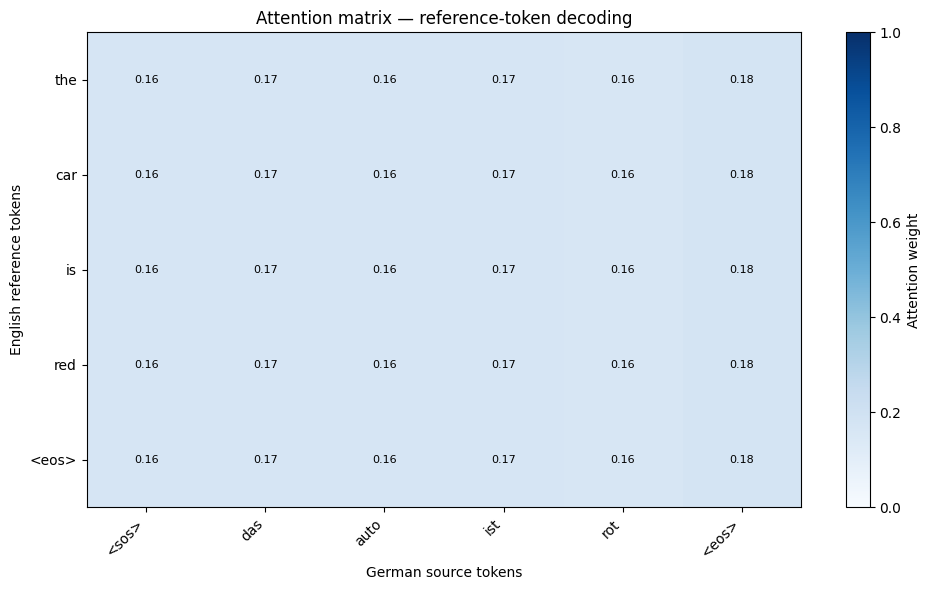

In [17]:
import matplotlib.pyplot as plt

source, reference = valid_pairs[0]
src, lengths = source_tensor(source)
target_ids = encode_text(reference, tgt_vocab)

attention_model.eval()
rows = []

with torch.no_grad():
    outputs, (hidden, cell) = attention_model.encoder(src, lengths)

    # Use each previous reference token to inspect attention.
    for token_id in target_ids[:-1]:
        previous = torch.tensor([token_id], device=device)

        _, hidden, cell, weights = attention_model.decoder(
            previous, hidden, cell, outputs, src.ne(PAD)
        )
        rows.append(weights[0].cpu())

matrix = torch.stack(rows).numpy()

source_labels = ["<sos>"] + tokenize(source) + ["<eos>"]
target_labels = tokenize(reference) + ["<eos>"]

print("Attention matrix shape:", matrix.shape)
print(matrix.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=0, vmax=1)

ax.set_xticks(range(len(source_labels)), source_labels,
              rotation=45, ha="right")
ax.set_yticks(range(len(target_labels)), target_labels)

for row in range(matrix.shape[0]):
    for col in range(matrix.shape[1]):
        ax.text(col, row, f"{matrix[row, col]:.2f}",
                ha="center", va="center", fontsize=8)

ax.set_xlabel("German source tokens")
ax.set_ylabel("English reference tokens")
ax.set_title("Attention matrix — reference-token decoding")
fig.colorbar(image, ax=ax, label="Attention weight")
plt.tight_layout()
plt.show()

7. Written answers and submission notes
Exercise 2 — attention. Repeat the previous decoder hidden state over source positions, concatenate it with each encoder output, apply a shared tanh projection and scalar scorer, mask source padding before softmax, and form a weighted sum. The context and weights stay attached to autograd. The source mask prevents attention to padding; the loss mask separately excludes target padding.

Exercise 3 — controlled comparison. Both runs share training/validation/test splits, tokenizer, training-only vocabularies, batch order, seed, hidden size, optimizer, teacher forcing, and epoch limit. Attention adds parameters, so the printed counts must be reported. Validation selects the saved-in-memory model state; test data does not choose settings. Smoke outputs cannot establish convergence or a benefit from attention.

Exercise 5 — metrics. Lower teacher-forced perplexity can coexist with lower BLEU because inference uses generated prefixes, errors accumulate, and BLEU measures overlap of decoded sentences rather than reference-token probabilities. Beam search changes the decoding procedure, not the model's teacher-forced reference probabilities. Use the measured four-row table and short/long/failure translations to decide whether attention helped in your run. Similar scores support a limited conclusion rather than a claim of improvement.

Exercise 6 — attention interpretation. For a generated noun, inspect its row and identify which German source positions receive high weights. Repeat for another output token and for a failed translation; describe the actual visible peaks or diffuse patterns. This decoder recomputes attention at each English generation step. A sequence-to-one classifier instead aggregates representations for one sequence-level prediction. Attention weights refer to contextual encoder representations and do not prove causal importance or one-to-one word alignment.

Complete after the full run: record both models' parameter counts, actual training and evaluation sizes, four metric rows, and visible translation errors (for example missing words, wrong nouns, repetition, or premature ending). Explain any missing exact-match success rather than invent one. Plots and metrics are saved in seq2seq_attention_outputs/; submit the executed notebook. No measured full-training results are bundled.